# 23 — Agglomerative Hierarchical Clustering (Clustering Track)
**23CSE301 Machine Learning — Capstone, Review 2**

**Dataset:** Customer Personality Analysis (`marketing_campaign.csv`) — 2,240 customers of a retail company
**Task:** unsupervised customer segmentation — **there is no target column to predict**

| Block | Rubric section |
|---|---|
| 1 | Section A — Dataset & EDA |
| 2 | Section B — Preprocessing & Feature Engineering |
| 3 | Review 2, Section B — Clustering Track (Agglomerative Hierarchical) |

Agglomerative clustering starts with every customer as their own cluster and repeatedly merges the two closest clusters until one is left. The record of those merges is the **dendrogram**, and cutting it at a chosen height gives the segmentation. Unlike K-Means it needs no starting centroids and is deterministic, but it is O(n²) in memory, and the **linkage** rule — ward, complete, average or single — changes the answer completely, so all four are compared below.

> **Rule for this track (guideline 3.3):** the labels that exist in this dataset (`Response`, the campaign
> acceptance flags) are **never** used while fitting. They are only brought back at the end, to interpret
> whether the segments the algorithm found mean anything commercially.

---
# BLOCK 1 — Dataset & EDA (Section A)

In [1]:
# ============================================================
# BLOCK 1 : DATASET & EDA
# ============================================================

# ---- 1.0 Imports & global settings ----
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # fixed seed for reproducibility (guideline 7.1)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")   # colour-blind-friendly palette (guideline 7.3)
pd.set_option("display.max_columns", 60)

DATA_PATH = "../data/marketing_campaign.csv"   # change if your file is somewhere else

**Note on the file format:** the Kaggle download is **tab-separated**, while some mirrors ship the same data
semicolon-separated. The loader below detects the separator instead of assuming one, so the notebook runs on either copy.

In [2]:
# ---- 1.1 Load the dataset (separator auto-detected) ----
with open(DATA_PATH, encoding="utf-8-sig") as fh:
    header = fh.readline()
sep = max(["\t", ";", ","], key=header.count)
print("Detected separator:", repr(sep))

df = pd.read_csv(DATA_PATH, sep=sep, encoding="utf-8-sig")
print("Shape (rows, columns):", df.shape)
df.head()

Detected separator: ';'
Shape (rows, columns): (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## A1 — Dataset loading & audit

| Group | Columns |
|---|---|
| **Who the customer is** | `Year_Birth`, `Education`, `Marital_Status`, `Income`, `Kidhome`, `Teenhome`, `Dt_Customer` |
| **What they spend on (2 years)** | `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` |
| **How they buy** | `NumDealsPurchases`, `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases`, `NumWebVisitsMonth` |
| **Campaign response** | `AcceptedCmp1`–`AcceptedCmp5`, `Response`, `Complain` — **held back for post-hoc interpretation only** |
| **Constants** | `Z_CostContact`, `Z_Revenue` — same value for every row |

In [3]:
# ---- 1.2 Data types, missing values, duplicates & constant columns ----
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate rows ignoring the ID column:", df.drop(columns=["ID"]).duplicated().sum())
print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])
audit

Exact duplicate rows: 0
Duplicate rows ignoring the ID column: 182
Constant columns: ['Z_CostContact', 'Z_Revenue']


,dtype,missing_count,missing_%,n_unique
ID,int64,0,0.00,2240
Year_Birth,int64,0,0.00,59
Education,str,0,0.00,5
Marital_Status,str,0,0.00,8
Income,float64,24,1.07,1974
Kidhome,int64,0,0.00,3
Teenhome,int64,0,0.00,3
Dt_Customer,str,0,0.00,663
Recency,int64,0,0.00,100
MntWines,int64,0,0.00,776


**📝 What this shows:** 182 customers are exact duplicates once the ID column is ignored, `Income` is missing for 24 people (1.1%), and `Z_CostContact` and `Z_Revenue` hold the same value for every row, so they carry no information at all.

In [4]:
# ---- 1.3 Statistical summary of the numeric columns ----
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.16,3246.66,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0


**📝 What this shows:** Spending is wildly uneven — wine averages 304 against a median of 174 and a maximum of 1,493 — and `Income` runs from 1,730 up to 666,666, which is not a real salary.

## A2 — EDA visualisations

There is no target distribution to plot in an unsupervised problem, so the equivalent first question is
**how the customers are spread out** — that spread is exactly what the clustering has to carve up.

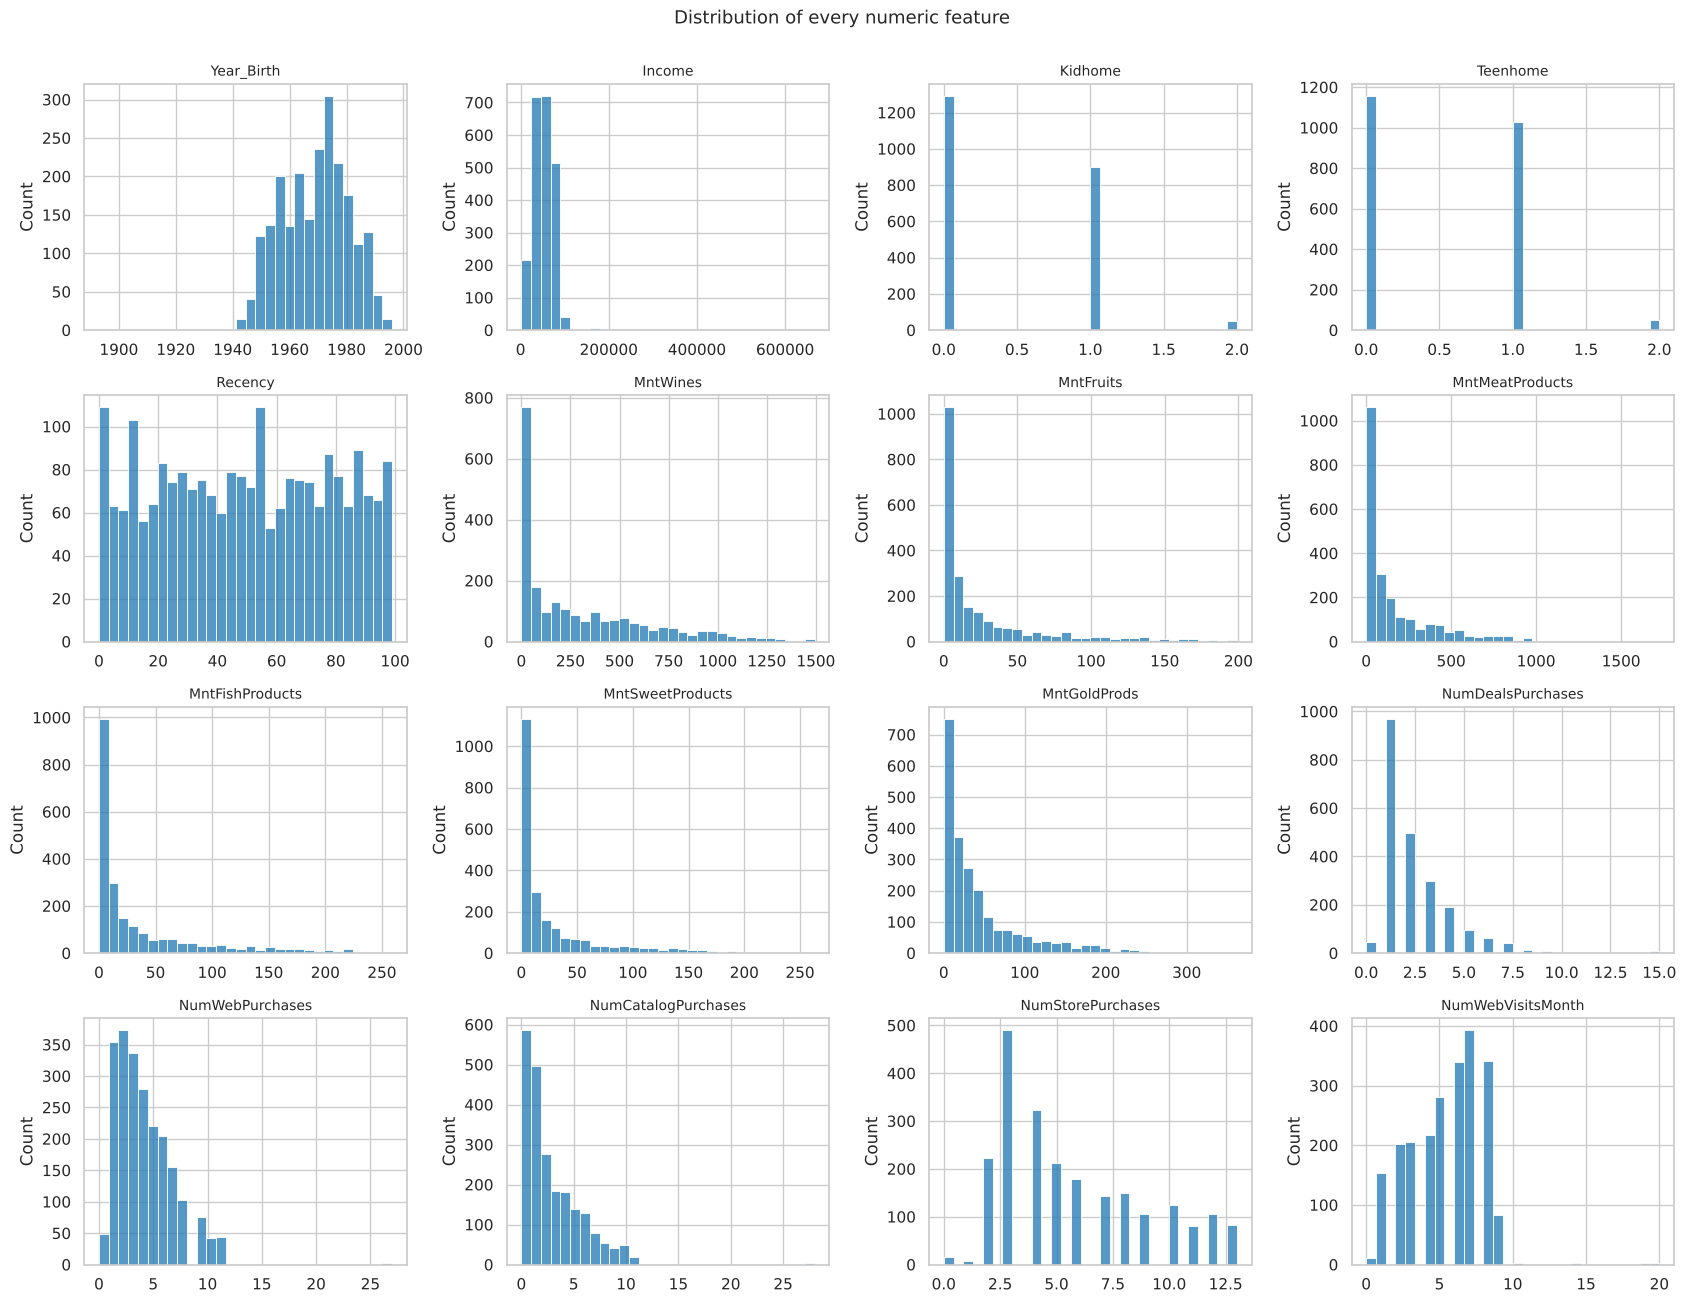

Skewness of the spending columns:
MntWines            1.18
MntFruits           2.10
MntMeatProducts     2.08
MntFishProducts     1.92
MntSweetProducts    2.14
MntGoldProds        1.89
dtype: float64


In [5]:
# ---- 1.4 Distribution of each numeric feature ----
raw_num = ["Year_Birth", "Income", "Kidhome", "Teenhome", "Recency", "MntWines", "MntFruits",
           "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds",
           "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
           "NumWebVisitsMonth"]

fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, col in zip(axes.flat, raw_num):
    sns.histplot(df[col].dropna(), bins=30, ax=ax, color="tab:blue")
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("Count")
plt.suptitle("Distribution of every numeric feature", y=1.001, fontsize=13)
plt.tight_layout(); plt.show()

print("Skewness of the spending columns:")
print(df[[c for c in raw_num if c.startswith("Mnt")]].skew().round(2))

**📝 What this shows:** Every spending column is right-skewed (skew 1.2 to 2.1): most customers buy very little while a small group buys a great deal, and that lopsidedness is exactly the structure a segmentation has to capture.

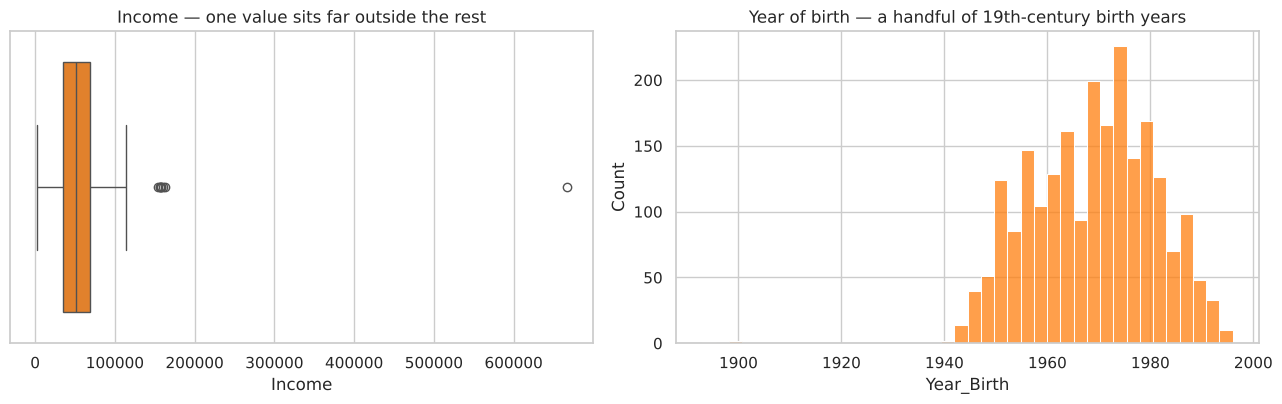

Incomes above 150,000:
 164     157243.0
617     162397.0
655     153924.0
687     160803.0
1300    157733.0
1653    157146.0
2132    156924.0
2233    666666.0

Birth years before 1940:
 192    1900
239    1893
339    1899


In [6]:
# ---- 1.5 The two columns with impossible values ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(x=df["Income"], ax=axes[0], color="tab:orange")
axes[0].set_title("Income — one value sits far outside the rest")
axes[0].set_xlabel("Income")

sns.histplot(df["Year_Birth"], bins=40, ax=axes[1], color="tab:orange")
axes[1].set_title("Year of birth — a handful of 19th-century birth years")
axes[1].set_xlabel("Year_Birth"); axes[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

print("Incomes above 150,000:\n", df.loc[df["Income"] > 150000, "Income"].to_string())
print("\nBirth years before 1940:\n", df.loc[df["Year_Birth"] < 1940, "Year_Birth"].to_string())

**📝 What this shows:** One customer reports an income of 666,666 against a median of 51,381, and three were born in 1893, 1899 and 1900 — these are data-entry errors, not customers.

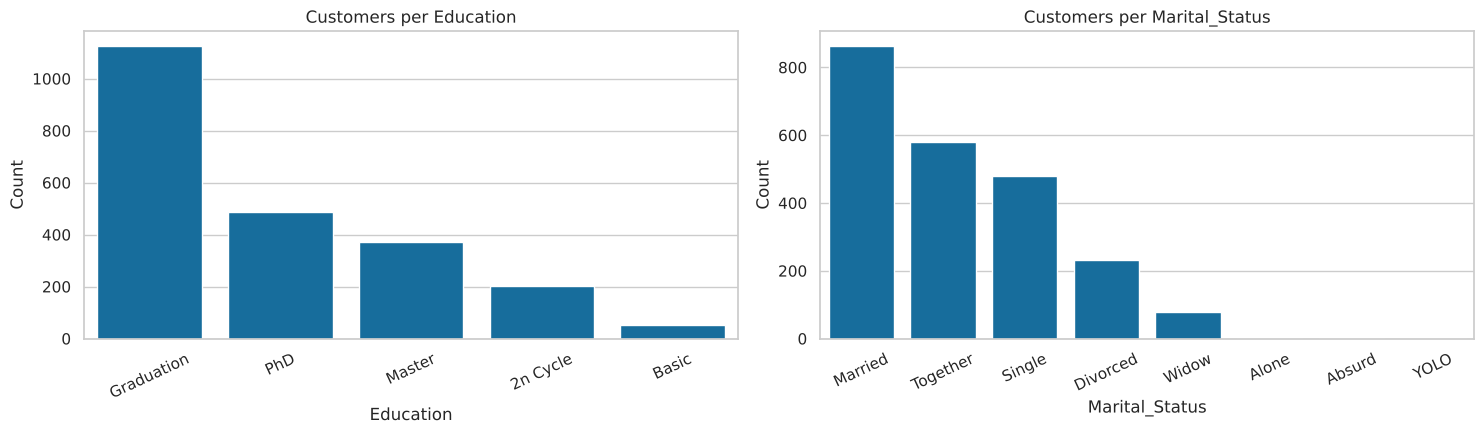

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2


In [7]:
# ---- 1.6 Categorical features ----
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ["Education", "Marital_Status"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Customers per {col}")
    ax.set_xlabel(col); ax.set_ylabel("Count"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

print(df["Marital_Status"].value_counts().to_string())

**📝 What this shows:** Half the customers are graduates, and `Marital_Status` carries three junk categories — Alone, Absurd and YOLO — covering seven people between them.

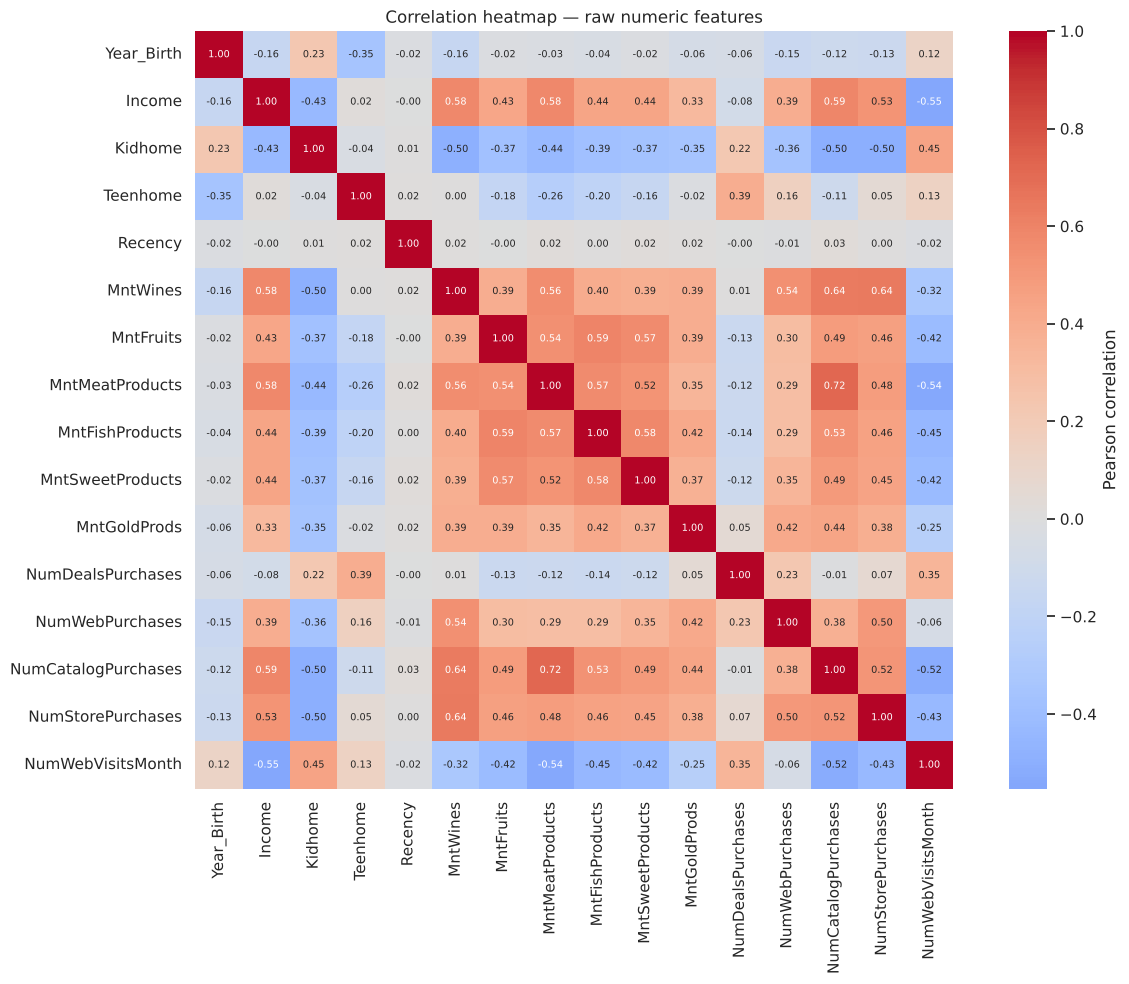

In [8]:
# ---- 1.7 Correlation heatmap ----
plt.figure(figsize=(13, 10))
corr = df[raw_num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            annot_kws={"size": 7}, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation heatmap — raw numeric features")
plt.tight_layout(); plt.show()

**📝 What this shows:** Meat spending and catalogue purchases move together most strongly (0.72), income tracks wine and meat spending at about 0.58, and web visits *fall* as income rises (-0.55) — the people browsing the site most often are the ones buying least.

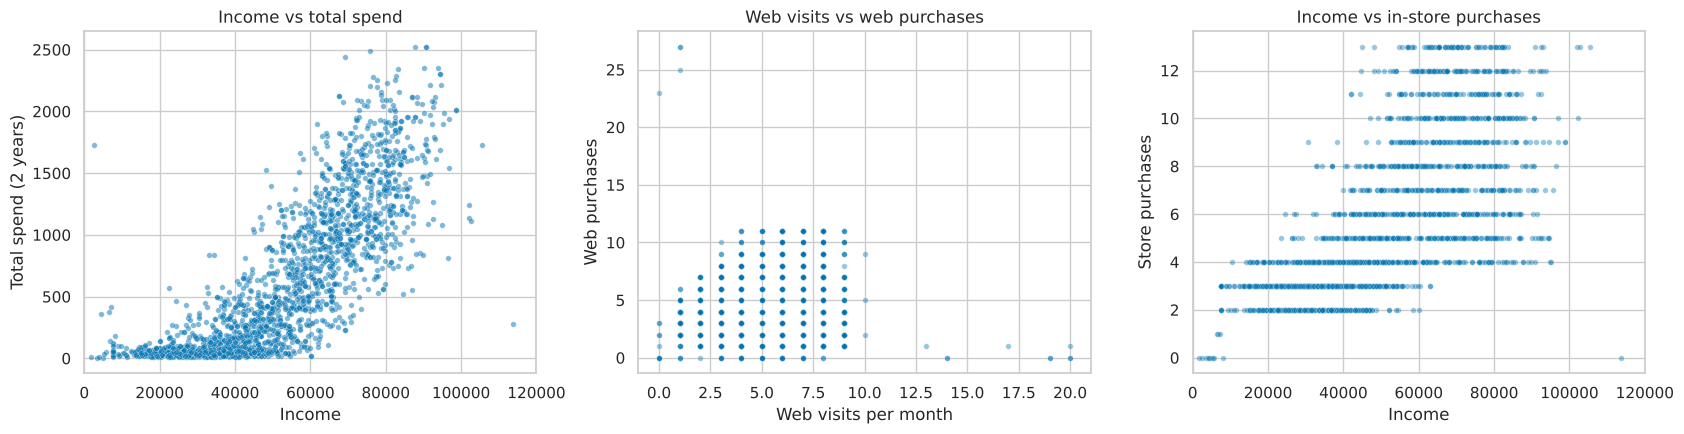

In [9]:
# ---- 1.8 Scatter plots: the relationships a segmentation will hang on ----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
spend_cols = [c for c in df.columns if c.startswith("Mnt")]
tmp = df.assign(TotalSpend=df[spend_cols].sum(axis=1))

sns.scatterplot(data=tmp, x="Income", y="TotalSpend", alpha=0.5, s=16, ax=axes[0])
axes[0].set_xlim(0, 120000)
axes[0].set_title("Income vs total spend"); axes[0].set_xlabel("Income"); axes[0].set_ylabel("Total spend (2 years)")

sns.scatterplot(data=tmp, x="NumWebVisitsMonth", y="NumWebPurchases", alpha=0.4, s=16, ax=axes[1])
axes[1].set_title("Web visits vs web purchases")
axes[1].set_xlabel("Web visits per month"); axes[1].set_ylabel("Web purchases")

sns.scatterplot(data=tmp, x="Income", y="NumStorePurchases", alpha=0.4, s=16, ax=axes[2])
axes[2].set_xlim(0, 120000)
axes[2].set_title("Income vs in-store purchases")
axes[2].set_xlabel("Income"); axes[2].set_ylabel("Store purchases")
plt.tight_layout(); plt.show()

**📝 What this shows:** Income and total spend rise together but fan out sharply above 60,000, and the middle plot shows the opposite of what you would expect: more web visits go with fewer web purchases.

---
# BLOCK 2 — Preprocessing & Feature Engineering (Section B)

In [10]:
# ============================================================
# BLOCK 2 : PREPROCESSING & FEATURE ENGINEERING
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ---- 2.1 Drop the columns that carry no information ----
# Z_CostContact and Z_Revenue are constants; ID is a row identifier.
df = df.drop(columns=["Z_CostContact", "Z_Revenue", "ID"], errors="ignore")

# ---- 2.2 Remove duplicate customers ----
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}  ->  rows now: {len(df)}")

Duplicates removed: 182  ->  rows now: 2058


**Missing-value strategy (justified):**

| Column | Missing | Strategy | Why |
|---|---|---|---|
| `Income` | 24 (1.1%) | fill with the **median income of the same education level** | Dropping 24 paying customers loses real segment members. Income is strongly right-skewed, so the **median** is used rather than the mean, and conditioning on education keeps the imputed values realistic instead of flattening everyone to one number. |

**Outlier strategy — different from the classification track.** In the classification notebooks outliers were *capped*,
because every labelled promotion was worth keeping. Clustering is **not** that forgiving: K-Means minimises squared
distance, so a single customer earning 666,666 drags a centroid towards itself and can own an entire cluster.
The handful of physically impossible rows are therefore **removed**, not capped.

In [11]:
# ---- 2.3 Missing values: income imputed within education level ----
print("Missing before:", df["Income"].isnull().sum())
df["Income"] = df["Income"].fillna(df.groupby("Education")["Income"].transform("median"))
print("Missing after :", int(df.isnull().sum().sum()))

# ---- 2.4 Remove impossible / extreme rows ----
before = len(df)
df = df[(df["Year_Birth"] >= 1940) & (df["Income"] <= 150000)].reset_index(drop=True)
print(f"Rows removed as outliers: {before - len(df)}  ->  rows now: {len(df)}")

Missing before: 24
Missing after : 0
Rows removed as outliers: 11  ->  rows now: 2047


## B3 — Feature engineering

In [12]:
# ---- 2.5 Engineered features ----
# Dt_Customer is parsed with dayfirst=True so both the dd-mm-yyyy (Kaggle) and yyyy-mm-dd (mirror) layouts work.
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True, format="mixed")
SNAPSHOT = df["Dt_Customer"].max() + pd.Timedelta(days=1)   # the day after the last enrolment = "today"
print("Snapshot date used as 'today':", SNAPSHOT.date())

spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
purchase_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]

df["Age"] = SNAPSHOT.year - df["Year_Birth"]                      # (1) age at the snapshot date
df["Tenure_days"] = (SNAPSHOT - df["Dt_Customer"]).dt.days        # (2) how long they have been a customer
df["TotalSpend"] = df[spend_cols].sum(axis=1)                     # (3) total value over two years
df["TotalPurchases"] = df[purchase_cols].sum(axis=1)              # (4) total transactions
df["Children"] = df["Kidhome"] + df["Teenhome"]                   # (5) children at home
df["Family_Size"] = df["Children"] + df["Marital_Status"].isin(
    ["Married", "Together"]).astype(int) + 1                      # (6) household size
df["AvgOrderValue"] = df["TotalSpend"] / df["TotalPurchases"].replace(0, np.nan)
df["AvgOrderValue"] = df["AvgOrderValue"].fillna(0)               # (7) spend per transaction
df["CampaignsAccepted"] = df[cmp_cols].sum(axis=1)                # (8) HELD BACK — post-hoc only
df["WineShare"] = df["MntWines"] / df["TotalSpend"].replace(0, np.nan)
df["WineShare"] = df["WineShare"].fillna(0)                       # (9) share of wallet going to wine

# tidy the two categorical columns
df["Education_level"] = df["Education"].replace({"2n Cycle": "Master", "Graduation": "Graduate",
                                                 "Basic": "Undergraduate"})
df["Living_With_Partner"] = df["Marital_Status"].isin(["Married", "Together"]).astype(int)

df[["Age", "Tenure_days", "TotalSpend", "TotalPurchases", "Children", "Family_Size",
    "AvgOrderValue", "WineShare"]].describe().T.round(2)

Snapshot date used as 'today': 2014-12-07


,count,mean,std,min,25%,50%,75%,max
Age,2047.0,45.12,11.67,18.0,37.00,44.00,55.00,74.00
Tenure_days,2047.0,512.22,232.58,1.0,340.00,513.00,686.00,1064.00
TotalSpend,2047.0,605.96,601.52,5.0,69.00,397.00,1044.50,2525.00
TotalPurchases,2047.0,14.88,7.60,0.0,8.00,15.00,21.00,43.00
Children,2047.0,0.96,0.75,0.0,0.00,1.00,1.00,3.00
Family_Size,2047.0,2.60,0.91,1.0,2.00,3.00,3.00,5.00
AvgOrderValue,2047.0,33.37,46.30,0.0,9.59,23.50,45.36,1679.00
WineShare,2047.0,0.46,0.23,0.0,0.29,0.46,0.64,0.96


**Why these features may help the clustering:**

- `Age`, `Tenure_days` — raw `Year_Birth` and a date are not distances a clustering algorithm can use; years-old and
  days-enrolled are.
- `TotalSpend`, `TotalPurchases`, `AvgOrderValue` — the classic **monetary / frequency** pair behind RFM segmentation,
  plus basket size, which separates "buys often, spends little" from "buys rarely, spends a lot".
- `Children`, `Family_Size` — `Kidhome` and `Teenhome` on their own split a signal that marketing treats as one.
- `WineShare` — wine is 50% of all spending in this dataset, so the *share* of wallet it takes tells the segments apart
  better than the raw amount, which mostly just re-states income.
- `Education_level`, `Living_With_Partner` — collapses rare and overlapping categories (`2n Cycle` ≈ Master,
  `Alone`/`Absurd`/`YOLO` ≈ single) so that one-hot encoding does not create near-empty dimensions that distort distance.

In [13]:
# ---- 2.6 Build the clustering feature matrix ----
# Campaign responses and Complain are deliberately EXCLUDED: they are the outcome we want to interpret
# the clusters against afterwards (guideline 3.3).
cluster_num = ["Age", "Income", "Tenure_days", "Recency", "Children", "Family_Size",
               "TotalSpend", "TotalPurchases", "AvgOrderValue", "WineShare",
               "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
               "MntSweetProducts", "MntGoldProds",
               "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
               "NumStorePurchases", "NumWebVisitsMonth"]
cluster_cat = ["Education_level"]

X = pd.get_dummies(df[cluster_num + cluster_cat + ["Living_With_Partner"]],
                   columns=cluster_cat, drop_first=True)
print("Feature matrix:", X.shape)
print("Columns:", list(X.columns))

Feature matrix: (2047, 25)
Columns: ['Age', 'Income', 'Tenure_days', 'Recency', 'Children', 'Family_Size', 'TotalSpend', 'TotalPurchases', 'AvgOrderValue', 'WineShare', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Living_With_Partner', 'Education_level_Master', 'Education_level_PhD', 'Education_level_Undergraduate']


**Scaling — and why there is no train/test split here.** Supervised tracks fit the scaler on the training split only,
to stop test information leaking into training. Clustering has **no labels and no test set**: every row is used to
find the structure, so the scaler is fitted on all of it. Nothing leaks, because nothing is being predicted.

Scaling itself is non-negotiable: `Income` runs to six figures while `Children` runs 0–3, and K-Means measures plain
Euclidean distance. Without standardisation the segmentation would be an income segmentation and nothing else.

In [14]:
# ---- 2.7 Standardise every feature ----
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.astype(float))
print("Scaled matrix:", X_scaled.shape)
print("Mean of each column after scaling (should be ~0):", np.round(X_scaled.mean(axis=0)[:5], 6))
print("Std of each column after scaling (should be ~1) :", np.round(X_scaled.std(axis=0)[:5], 6))

Scaled matrix: (2047, 25)
Mean of each column after scaling (should be ~0): [-0.  0.  0. -0. -0.]
Std of each column after scaling (should be ~1) : [1. 1. 1. 1. 1.]


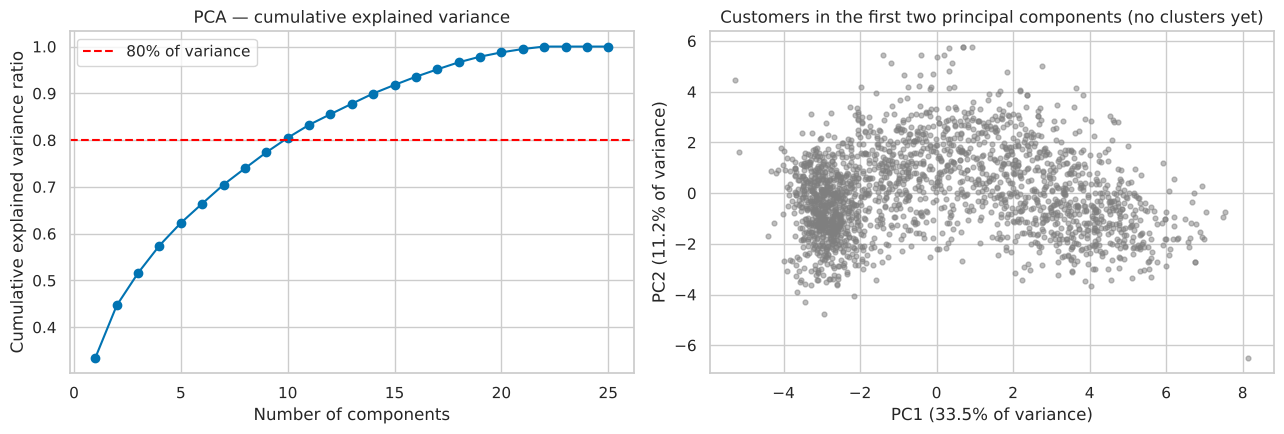

Variance explained by PC1 + PC2: 44.7%
Components needed for 80%: 10


In [15]:
# ---- 2.8 PCA — used for visualisation, and to show how much structure 2 components keep ----
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
             np.cumsum(pca_full.explained_variance_ratio_), marker="o")
axes[0].axhline(0.8, color="red", linestyle="--", label="80% of variance")
axes[0].set_title("PCA — cumulative explained variance")
axes[0].set_xlabel("Number of components"); axes[0].set_ylabel("Cumulative explained variance ratio")
axes[0].legend()

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], s=12, alpha=0.5, color="tab:grey")
axes[1].set_title("Customers in the first two principal components (no clusters yet)")
axes[1].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%} of variance)")
axes[1].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%} of variance)")
plt.tight_layout(); plt.show()

print("Variance explained by PC1 + PC2: %.1f%%" % (100 * pca2.explained_variance_ratio_.sum()))
print("Components needed for 80%%: %d" % (np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.8) + 1))

**📝 What this shows:** The first two components keep 44.7% of the variance (33.5% and 11.2%) and ten of the 25 are needed to reach 80%, so the PCA scatter plots below are a readable summary of the structure, not the whole of it.

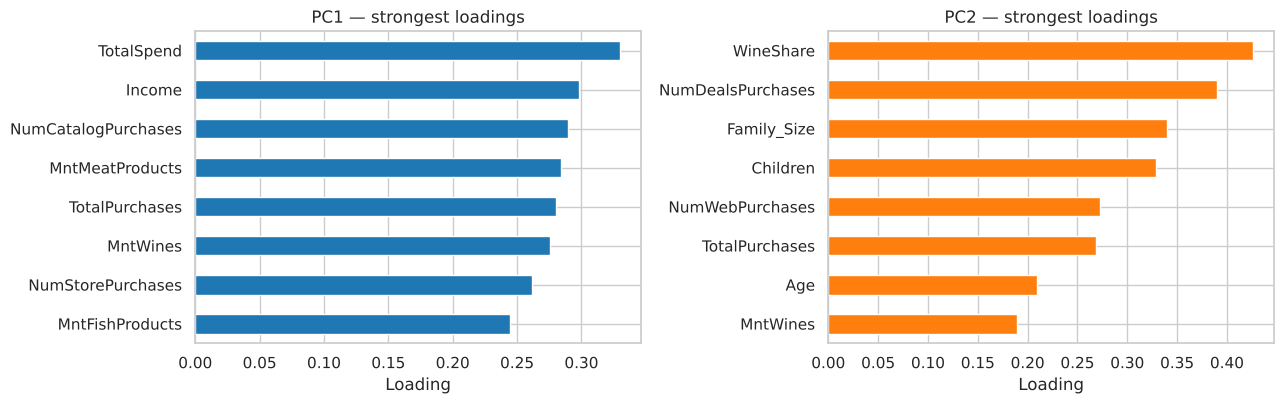

In [16]:
# ---- 2.9 What do the first two principal components actually mean? ----
loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=["PC1", "PC2"])
top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(8).index
top_pc2 = loadings["PC2"].abs().sort_values(ascending=False).head(8).index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
loadings.loc[top_pc1, "PC1"].sort_values().plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("PC1 — strongest loadings"); axes[0].set_xlabel("Loading")
loadings.loc[top_pc2, "PC2"].sort_values().plot(kind="barh", ax=axes[1], color="tab:orange")
axes[1].set_title("PC2 — strongest loadings"); axes[1].set_xlabel("Loading")
plt.tight_layout(); plt.show()

**📝 What this shows:** PC1 is a pure customer-value axis — total spend, income, catalogue purchases and meat all load on it positively — while PC2 separates deal-hunting families (wine share, deals purchases, family size, children) from everyone else.

In [17]:
# ---- 2.10 Shared metric helper for the clustering track ----
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def cluster_metrics(X_mat, labels):
    # All three are MANDATORY for this track. None of them uses the ground-truth labels.
    #   Silhouette        : -1 to 1, higher is better (separation vs cohesion)
    #   Davies-Bouldin    : 0 upwards, LOWER is better (average similarity between a cluster and its closest neighbour)
    #   Calinski-Harabasz : higher is better (between-cluster vs within-cluster dispersion)
    k = len(set(labels)) - (1 if -1 in labels else 0)
    return {
        "n_clusters": k,
        "Silhouette": silhouette_score(X_mat, labels),
        "Davies_Bouldin": davies_bouldin_score(X_mat, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_mat, labels),
    }

---
# BLOCK 3 — Clustering Track: Agglomerative Hierarchical Clustering (Review 2, Section B)

Linkage time: 0.2 s | merges recorded: 2046


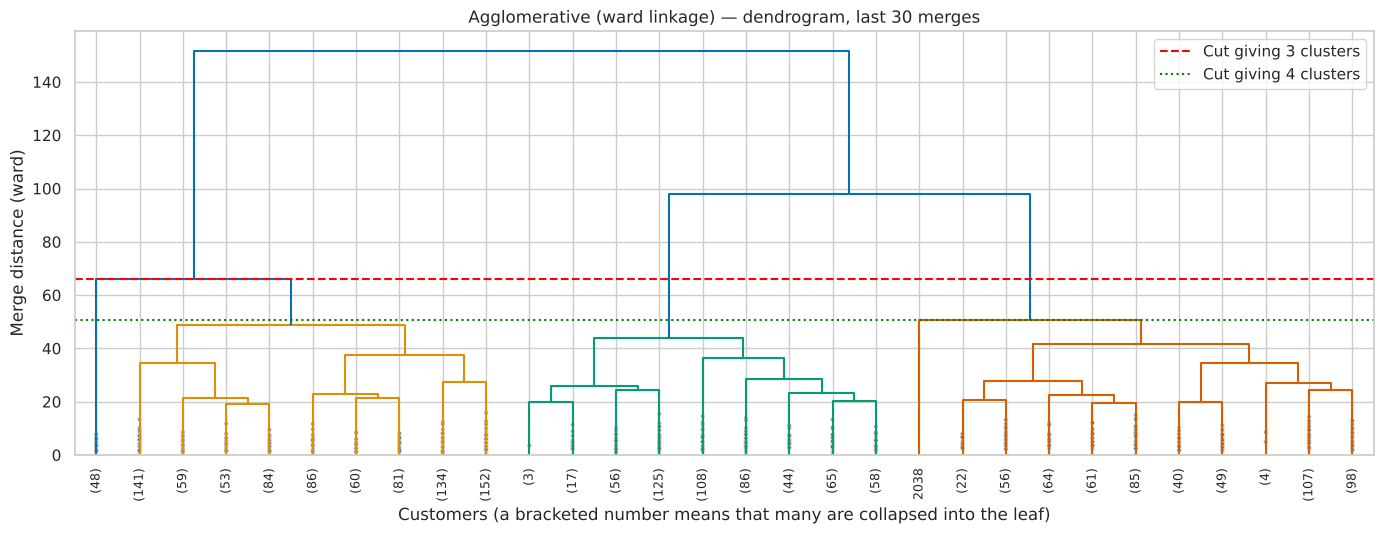

Distance at which the last merges happen (height of the cut):
9 clusters     37.48
8 clusters     41.53
7 clusters     43.94
6 clusters     48.96
5 clusters     50.76
4 clusters     66.14
3 clusters     97.94
2 clusters    151.53


In [18]:
# ============================================================
# BLOCK 3 : CLUSTERING — AGGLOMERATIVE HIERARCHICAL
# ============================================================
import time
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

# ---- 3.1 Dendrogram (mandatory for this algorithm) ----
start = time.time()
Z = linkage(X_scaled, method="ward")       # scipy returns the full merge history
print(f"Linkage time: {time.time() - start:.1f} s | merges recorded: {len(Z)}")

plt.figure(figsize=(14, 5.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=Z[-3, 2])
plt.title("Agglomerative (ward linkage) — dendrogram, last 30 merges")
plt.xlabel("Customers (a bracketed number means that many are collapsed into the leaf)")
plt.ylabel("Merge distance (ward)")
plt.axhline(Z[-3, 2], color="red", linestyle="--", label="Cut giving 3 clusters")
plt.axhline(Z[-4, 2], color="green", linestyle=":", label="Cut giving 4 clusters")
plt.legend(); plt.tight_layout(); plt.show()

print("Distance at which the last merges happen (height of the cut):")
print(pd.Series(Z[-8:, 2], index=[f"{i} clusters" for i in range(9, 1, -1)]).round(2).to_string())

**📝 What this shows:** The last two merges happen at distances of 97.9 and 151.5 against 50.8 for the fifth, so the tree itself says the data divides naturally into two groups, or three at a push.

## Comparing linkage strategies

The linkage rule defines *how far apart two clusters are*:

| Linkage | Distance between clusters | Typical behaviour |
|---|---|---|
| **ward** | increase in total within-cluster variance after merging | compact, similar-sized clusters; the usual default |
| **complete** | distance between the two **furthest** members | compact but sensitive to outliers |
| **average** | mean distance between all pairs of members | a compromise between the two above |
| **single** | distance between the two **closest** members | prone to *chaining* — long straggly clusters, often one giant cluster plus singletons |

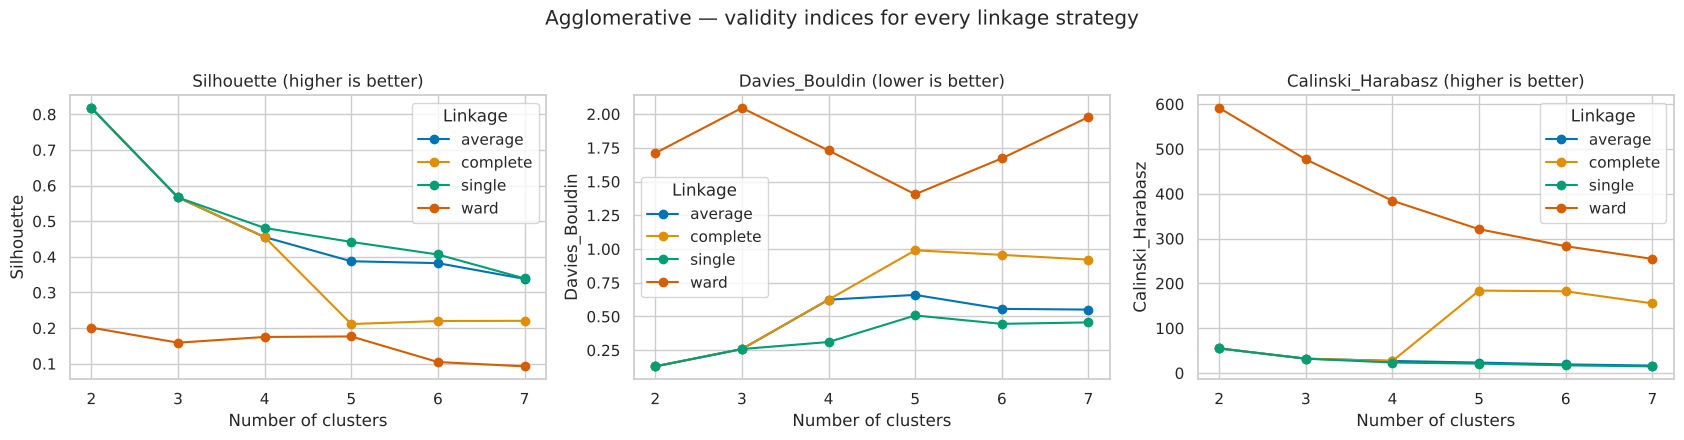

,linkage,n_clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,largest_cluster_%,smallest_cluster_%
0,ward,2,0.2013,1.7106,591.4955,56.1309,43.8691
1,ward,3,0.1591,2.0456,476.6700,43.8691,27.4548
2,ward,4,0.1751,1.7303,384.3903,41.5242,2.3449
3,ward,5,0.1766,1.4058,320.8922,41.5242,0.0489
4,ward,6,0.1048,1.6716,282.9507,28.6273,0.0489
5,ward,7,0.0926,1.9777,254.6728,28.6273,0.0489
6,complete,2,0.8180,0.1301,54.8920,99.9511,0.0489
7,complete,3,0.5666,0.2585,32.0213,99.9023,0.0489
8,complete,4,0.4555,0.6245,26.9404,99.7069,0.0489
9,complete,5,0.2114,0.9905,183.8931,50.8061,0.0489


In [19]:
# ---- 3.2 Every linkage x every cluster count ----
rows = []
for method in ["ward", "complete", "average", "single"]:
    for k in range(2, 8):
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X_scaled)
        sizes = pd.Series(labels).value_counts()
        rows.append({"linkage": method, **cluster_metrics(X_scaled, labels),
                     "largest_cluster_%": 100 * sizes.max() / len(labels),
                     "smallest_cluster_%": 100 * sizes.min() / len(labels)})
link_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for ax, (col, better) in zip(axes, [("Silhouette", "higher is better"),
                                    ("Davies_Bouldin", "lower is better"),
                                    ("Calinski_Harabasz", "higher is better")]):
    for method, part in link_df.groupby("linkage"):
        ax.plot(part["n_clusters"], part[col], marker="o", label=method)
    ax.set_title(f"{col} ({better})")
    ax.set_xlabel("Number of clusters"); ax.set_ylabel(col); ax.legend(title="Linkage")
plt.suptitle("Agglomerative — validity indices for every linkage strategy", y=1.02)
plt.tight_layout(); plt.show()

link_df.round(4)

**📝 What this shows:** Complete, average and single linkage all report a silhouette of 0.818 at k=2, which looks far better than ward's 0.201 — and is entirely an illusion, as the next cell shows.

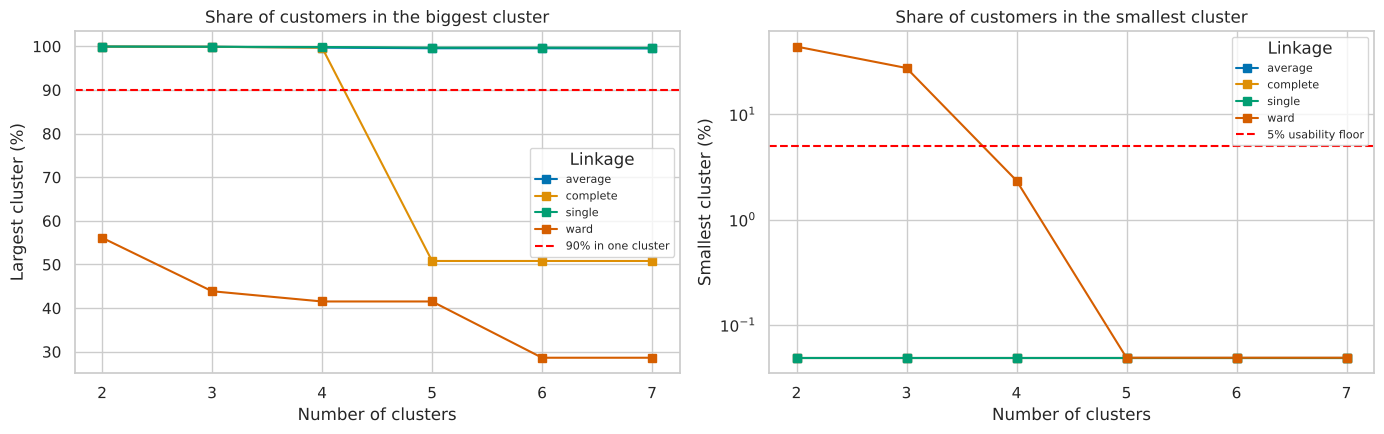

linkage,average,complete,single,ward
n_clusters,,,,
2,0.05,0.05,0.05,43.87
3,0.05,0.05,0.05,27.45
4,0.05,0.05,0.05,2.34
5,0.05,0.05,0.05,0.05
6,0.05,0.05,0.05,0.05
7,0.05,0.05,0.05,0.05


In [20]:
# ---- 3.3 Why the best silhouette scores here are a trap ----
# A silhouette of 0.82 with one cluster holding 99.95% of the customers is not a segmentation:
# it is one giant blob plus a single outlier sitting on its own. The cluster SIZES expose that
# immediately, which is why they are checked before any score is believed.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for method, part in link_df.groupby("linkage"):
    axes[0].plot(part["n_clusters"], part["largest_cluster_%"], marker="s", label=method)
    axes[1].plot(part["n_clusters"], part["smallest_cluster_%"], marker="s", label=method)
axes[0].axhline(90, color="red", linestyle="--", label="90% in one cluster")
axes[0].set_title("Share of customers in the biggest cluster")
axes[0].set_xlabel("Number of clusters"); axes[0].set_ylabel("Largest cluster (%)")
axes[0].legend(title="Linkage", fontsize=8)

axes[1].axhline(5, color="red", linestyle="--", label="5% usability floor")
axes[1].set_title("Share of customers in the smallest cluster")
axes[1].set_xlabel("Number of clusters"); axes[1].set_ylabel("Smallest cluster (%)")
axes[1].set_yscale("log"); axes[1].legend(title="Linkage", fontsize=8)
plt.tight_layout(); plt.show()

link_df.pivot(index="n_clusters", columns="linkage", values="smallest_cluster_%").round(2)

**📝 What this shows:** Those three linkages put 99.95% of the customers into one cluster and a single person into the other: textbook chaining. Ward is the only rule that cuts the data into usable pieces (56.1% / 43.9%).

In [21]:
# ---- 3.4 Fit the chosen model ----
# Selection rule, applied in this order:
#   (1) every cluster must hold at least 5% of the customers — a segment of 1 person cannot be marketed to;
#   (2) among the survivors, take the highest silhouette.
usable = link_df[link_df["smallest_cluster_%"] >= 5]
print("Configurations that pass the 5% usability rule:")
print(usable[["linkage", "n_clusters", "Silhouette", "Davies_Bouldin",
              "Calinski_Harabasz", "smallest_cluster_%"]].round(4).to_string(index=False))
best_row = usable.sort_values("Silhouette", ascending=False).iloc[0]
BEST_LINKAGE, BEST_K = best_row["linkage"], int(best_row["n_clusters"])
print(f"Chosen: linkage='{BEST_LINKAGE}', n_clusters={BEST_K}")

start = time.time()
agglo = AgglomerativeClustering(n_clusters=BEST_K, linkage=BEST_LINKAGE).fit(X_scaled)
print(f"Fit time: {time.time() - start:.2f} s")

df["Agglo_Cluster"] = agglo.labels_
agglo_scores = cluster_metrics(X_scaled, agglo.labels_)
print("Cluster sizes:", df["Agglo_Cluster"].value_counts().sort_index().to_dict())

# cophenetic correlation: how faithfully the dendrogram preserves the original distances
from scipy.cluster.hierarchy import cophenet
coph_corr, _ = cophenet(Z, pdist(X_scaled))
print("Cophenetic correlation of the ward dendrogram: %.4f" % coph_corr)
pd.Series(agglo_scores).round(4)

Configurations that pass the 5% usability rule:
linkage  n_clusters  Silhouette  Davies_Bouldin  Calinski_Harabasz  smallest_cluster_%
   ward           2      0.2013          1.7106           591.4955             43.8691
   ward           3      0.1591          2.0456           476.6700             27.4548
Chosen: linkage='ward', n_clusters=2
Fit time: 0.09 s


Cluster sizes: {0: 1149, 1: 898}


Cophenetic correlation of the ward dendrogram: 0.4400


n_clusters             2.0000
Silhouette             0.2013
Davies_Bouldin         1.7106
Calinski_Harabasz    591.4955
dtype: float64

## B3 — Cluster visualisation (PCA, t-SNE)

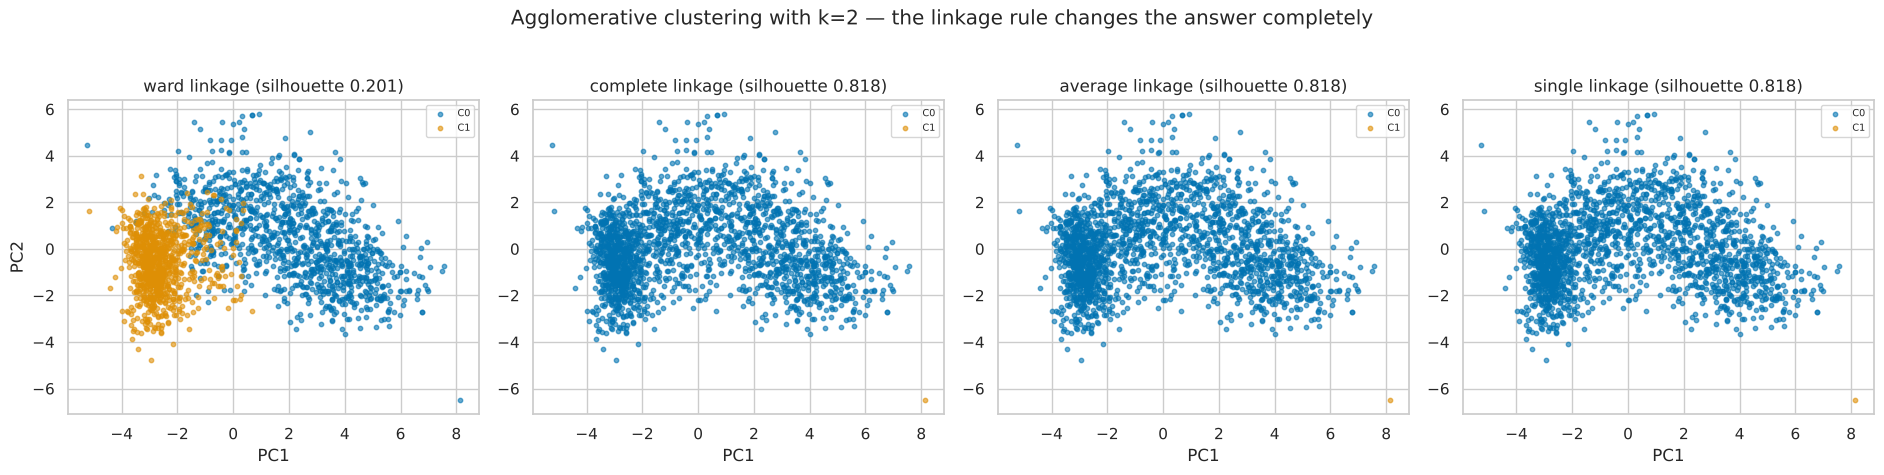

In [22]:
# ---- 3.5 PCA-reduced 2D scatter for every linkage strategy (mandatory for every algorithm) ----
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, method in zip(axes, ["ward", "complete", "average", "single"]):
    labels = AgglomerativeClustering(n_clusters=BEST_K, linkage=method).fit_predict(X_scaled)
    for c in sorted(set(labels)):
        m = labels == c
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=10, alpha=0.6, label=f"C{c}")
    sil = silhouette_score(X_scaled, labels)
    ax.set_title(f"{method} linkage (silhouette {sil:.3f})")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2" if method == "ward" else "")
    ax.legend(fontsize=7)
plt.suptitle(f"Agglomerative clustering with k={BEST_K} — the linkage rule changes the answer completely", y=1.03)
plt.tight_layout(); plt.show()

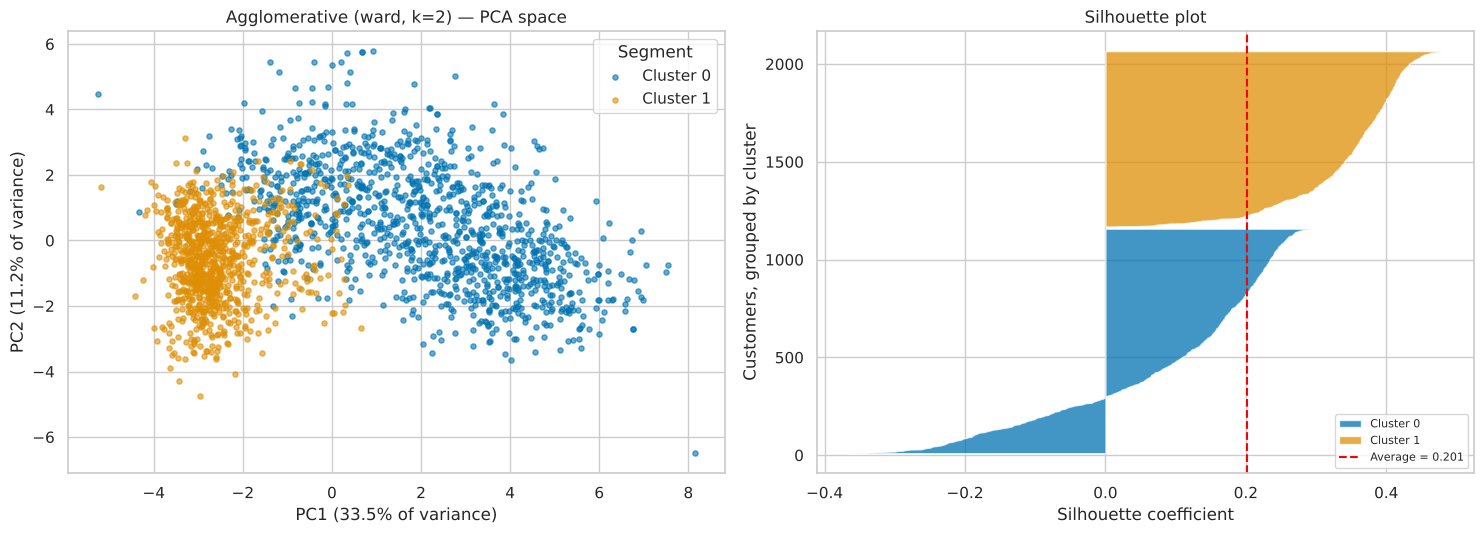

In [23]:
# ---- 3.6 The chosen model in PCA space, with per-customer silhouette ----
sample_sil = silhouette_samples(X_scaled, agglo.labels_)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for c in sorted(df["Agglo_Cluster"].unique()):
    m = (df["Agglo_Cluster"] == c).values
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=14, alpha=0.6, label=f"Cluster {c}")
axes[0].set_title(f"Agglomerative ({BEST_LINKAGE}, k={BEST_K}) — PCA space")
axes[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%} of variance)")
axes[0].legend(title="Segment")

y_lower = 10
for c in sorted(df["Agglo_Cluster"].unique()):
    vals = np.sort(sample_sil[agglo.labels_ == c])
    y_upper = y_lower + len(vals)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.75, label=f"Cluster {c}")
    y_lower = y_upper + 10
axes[1].axvline(agglo_scores["Silhouette"], color="red", linestyle="--",
                label=f"Average = {agglo_scores['Silhouette']:.3f}")
axes[1].set_title("Silhouette plot"); axes[1].set_xlabel("Silhouette coefficient")
axes[1].set_ylabel("Customers, grouped by cluster"); axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

t-SNE time: 45.1 s


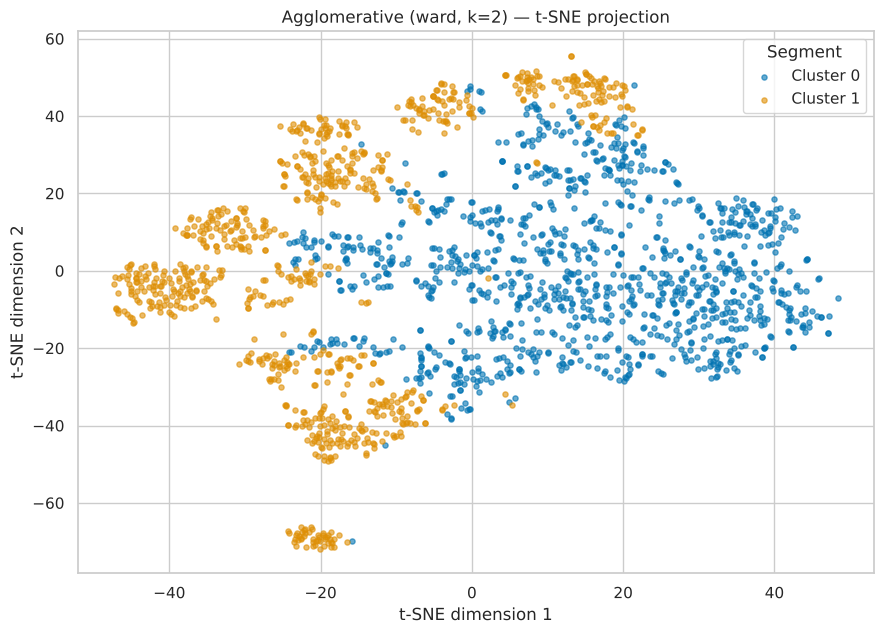

In [24]:
# ---- 3.7 t-SNE view ----
start = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)
print(f"t-SNE time: {time.time() - start:.1f} s")

plt.figure(figsize=(9, 6.5))
for c in sorted(df["Agglo_Cluster"].unique()):
    m = (df["Agglo_Cluster"] == c).values
    plt.scatter(X_tsne[m, 0], X_tsne[m, 1], s=14, alpha=0.6, label=f"Cluster {c}")
plt.title(f"Agglomerative ({BEST_LINKAGE}, k={BEST_K}) — t-SNE projection")
plt.xlabel("t-SNE dimension 1"); plt.ylabel("t-SNE dimension 2")
plt.legend(title="Segment"); plt.tight_layout(); plt.show()

**📝 What this shows:** The two ward clusters occupy the same regions of the t-SNE map that K-Means picked out, with the disagreement concentrated in the middle band where the groups meet.

## Interpreting the segments (Agglomerative)

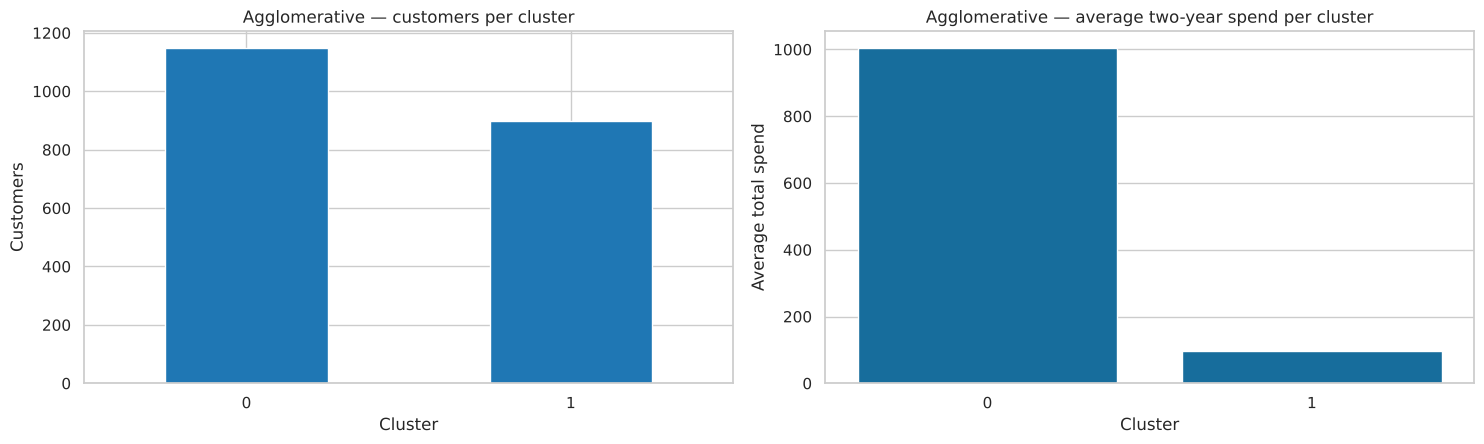

,customers,Age,Income,Tenure_days,Recency,Children,Family_Size,TotalSpend,TotalPurchases,AvgOrderValue,WineShare,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth
Agglo_Cluster,,,,,,,,,,,,,,,,
0,1149,47.2,65093.2,547.4,48.6,0.8,2.4,1005.0,20.5,50.9,0.5,5.7,4.3,7.8,2.7,4.5
1,898,42.5,34518.7,467.2,49.4,1.2,2.9,95.4,7.7,10.9,0.4,2.1,0.5,3.2,1.9,6.4


In [25]:
# ---- 3.8 Cluster sizes and average profile ----
profile_cols = ["Age", "Income", "Tenure_days", "Recency", "Children", "Family_Size",
                "TotalSpend", "TotalPurchases", "AvgOrderValue", "WineShare",
                "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
                "NumDealsPurchases", "NumWebVisitsMonth"]
profile = df.groupby("Agglo_Cluster")[profile_cols].mean()
profile.insert(0, "customers", df["Agglo_Cluster"].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
profile["customers"].plot(kind="bar", ax=axes[0], color="tab:blue")
axes[0].set_title("Agglomerative — customers per cluster")
axes[0].set_xlabel("Cluster"); axes[0].set_ylabel("Customers"); axes[0].tick_params(axis="x", rotation=0)

sns.barplot(data=df, x="Agglo_Cluster", y="TotalSpend", ax=axes[1], errorbar=None)
axes[1].set_title("Agglomerative — average two-year spend per cluster")
axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Average total spend")
plt.tight_layout(); plt.show()

profile.round(1)

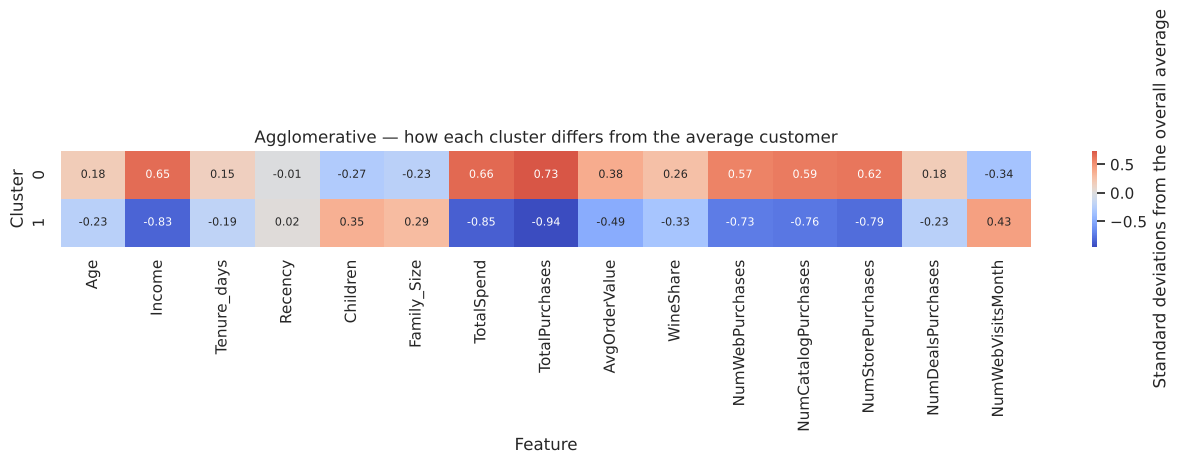

In [26]:
# ---- 3.9 Profile heatmap (z-scores, so every feature is on the same scale) ----
z = (profile[profile_cols] - df[profile_cols].mean()) / df[profile_cols].std()
plt.figure(figsize=(13, 3.6))
sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            cbar_kws={"label": "Standard deviations from the overall average"}, annot_kws={"size": 8})
plt.title("Agglomerative — how each cluster differs from the average customer")
plt.xlabel("Feature"); plt.ylabel("Cluster")
plt.tight_layout(); plt.show()

**📝 What this shows:** Cluster 0 (1,149 customers) earns 65,100 and spends 1,005; cluster 1 (898) earns 34,500 and spends 95 — the same high-value/low-value divide K-Means found, with the line drawn slightly further down.

## Post-hoc validation against the held-back labels

The campaign columns were kept out of the feature matrix. Bringing them back **now** is the honest test of whether the
segmentation means anything: if the clusters were noise, campaign acceptance would be flat across them.

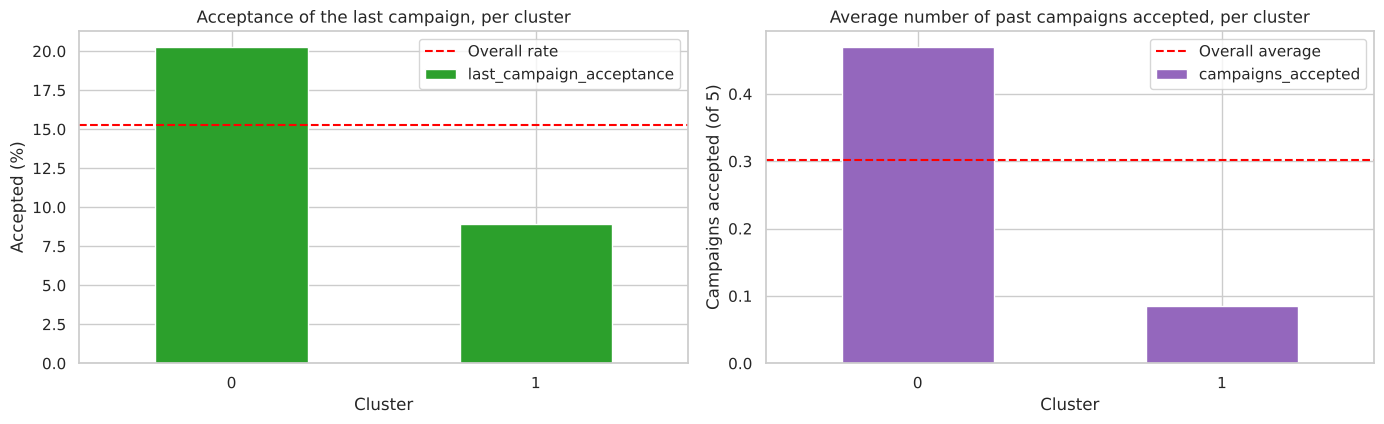

Education mix per cluster (%):
Education_level  Graduate  Master   PhD  Undergraduate
Agglo_Cluster                                         
0                    51.3    25.4  23.2            0.1
1                    48.8    26.1  19.8            5.3


,customers,last_campaign_acceptance,campaigns_accepted,complaint_rate
Agglo_Cluster,,,,
0,1149,20.279,0.470,0.008
1,898,8.909,0.086,0.011


In [27]:
# ---- 3.10 Campaign response per cluster (labels used ONLY here, after fitting) ----
resp = df.groupby("Agglo_Cluster").agg(
    customers=("Response", "size"),
    last_campaign_acceptance=("Response", "mean"),
    campaigns_accepted=("CampaignsAccepted", "mean"),
    complaint_rate=("Complain", "mean"),
)
resp["last_campaign_acceptance"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
resp["last_campaign_acceptance"].plot(kind="bar", ax=axes[0], color="tab:green")
axes[0].axhline(df["Response"].mean() * 100, color="red", linestyle="--", label="Overall rate")
axes[0].set_title("Acceptance of the last campaign, per cluster")
axes[0].set_xlabel("Cluster"); axes[0].set_ylabel("Accepted (%)")
axes[0].tick_params(axis="x", rotation=0); axes[0].legend()

resp["campaigns_accepted"].plot(kind="bar", ax=axes[1], color="tab:purple")
axes[1].axhline(df["CampaignsAccepted"].mean(), color="red", linestyle="--", label="Overall average")
axes[1].set_title("Average number of past campaigns accepted, per cluster")
axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Campaigns accepted (of 5)")
axes[1].tick_params(axis="x", rotation=0); axes[1].legend()
plt.tight_layout(); plt.show()

print("Education mix per cluster (%):")
print((pd.crosstab(df["Agglo_Cluster"], df["Education_level"], normalize="index") * 100).round(1))
resp.round(3)

**📝 What this shows:** 20.3% of cluster 0 accepted the last campaign against 8.9% of cluster 1, and the only group with a meaningful share of undergraduate-educated customers (5.3%) is the low-spending one.

---
## Consolidated clustering comparison (deliverable D7)

Using the K-Means labels saved by notebook 22.
Adjusted Rand Index between the two labellings : 0.4869
Normalised Mutual Information                  : 0.5095


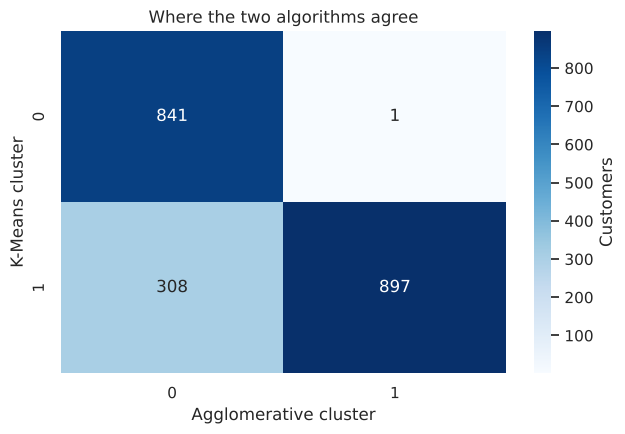

Agglo_Cluster,0,1
KMeans_Cluster,,
0,841,1
1,308,897


In [28]:
# ---- 3.11 Do the two algorithms find the same customers? ----
# The labels notebook 22 saved are reused when they are available, so the comparison is against the
# K-Means model that was actually reported, not a fresh one fitted with a different k.
KM_LABELS = "../results/kmeans_labels.csv"
if os.path.exists(KM_LABELS) and len(pd.read_csv(KM_LABELS)) == len(df):
    df["KMeans_Cluster"] = pd.read_csv(KM_LABELS)["KMeans_Cluster"].values
    print("Using the K-Means labels saved by notebook 22.")
else:
    k_km = BEST_K
    if os.path.exists("../results/clustering_results.csv"):
        prev = pd.read_csv("../results/clustering_results.csv")
        prev = prev[prev["Algorithm"] == "K-Means"]
        if len(prev):
            k_km = int(prev["n_clusters"].iloc[0])
    print(f"Saved labels not found — refitting K-Means with k={k_km}.")
    df["KMeans_Cluster"] = KMeans(n_clusters=k_km, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)

ari = adjusted_rand_score(df["KMeans_Cluster"], df["Agglo_Cluster"])
nmi = normalized_mutual_info_score(df["KMeans_Cluster"], df["Agglo_Cluster"])
print("Adjusted Rand Index between the two labellings : %.4f" % ari)
print("Normalised Mutual Information                  : %.4f" % nmi)

ct = pd.crosstab(df["KMeans_Cluster"], df["Agglo_Cluster"])
plt.figure(figsize=(6.5, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Customers"})
plt.title("Where the two algorithms agree")
plt.xlabel("Agglomerative cluster"); plt.ylabel("K-Means cluster")
plt.tight_layout(); plt.show()
ct

**📝 What this shows:** The two algorithms place 1,738 of 2,047 customers (84.9%, ARI 0.487) in matching clusters: they draw the same boundary, but ward pulls 308 middle-income customers into the high-value cluster that K-Means leaves on the other side.

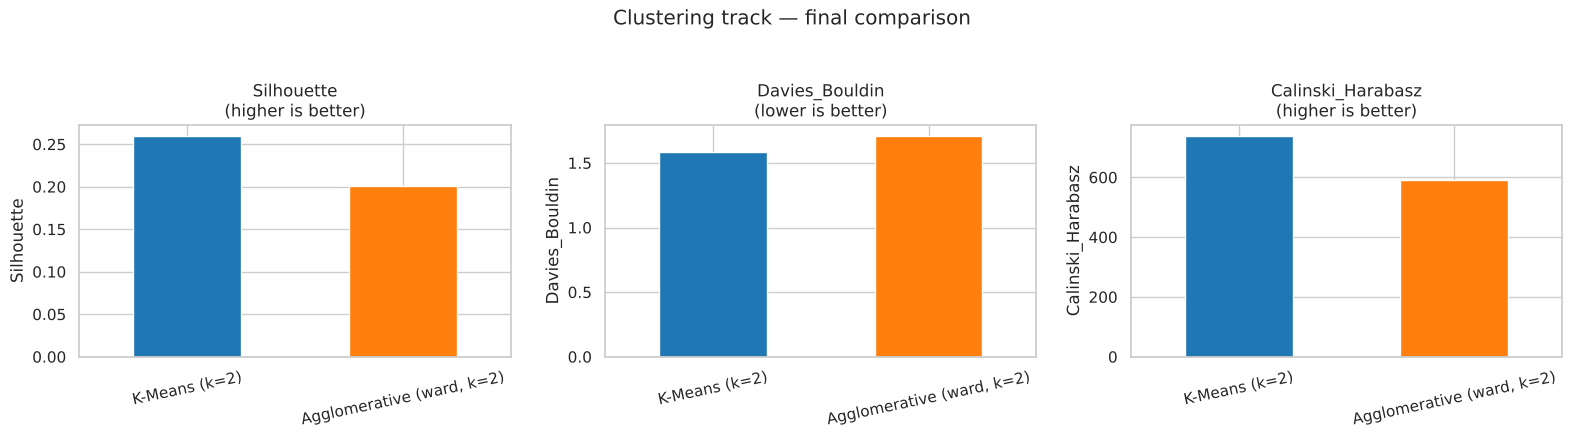

,n_clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Parameters
Model,,,,,
K-Means (k=2),2,0.2600,1.5843,739.1064,"n_clusters=2, n_init=20"
"Agglomerative (ward, k=2)",2,0.2013,1.7106,591.4955,"linkage=ward, n_clusters=2"


In [29]:
# ---- 3.12 Final comparison table across both required algorithms ----
os.makedirs("../results", exist_ok=True)
RESULTS_FILE = "../results/clustering_results.csv"

row = pd.DataFrame([{"Model": f"Agglomerative ({BEST_LINKAGE}, k={BEST_K})", "Algorithm": "Agglomerative",
                     **agglo_scores, "Parameters": f"linkage={BEST_LINKAGE}, n_clusters={BEST_K}"}])
if os.path.exists(RESULTS_FILE):
    old = pd.read_csv(RESULTS_FILE)
    row = pd.concat([old[old["Algorithm"] != "Agglomerative"], row], ignore_index=True)
row.to_csv(RESULTS_FILE, index=False)

final = pd.read_csv(RESULTS_FILE).set_index("Model")
display_cols = ["n_clusters", "Silhouette", "Davies_Bouldin", "Calinski_Harabasz", "Parameters"]
final = final[[c for c in display_cols if c in final.columns]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, better) in zip(axes, [("Silhouette", "higher is better"),
                                    ("Davies_Bouldin", "lower is better"),
                                    ("Calinski_Harabasz", "higher is better")]):
    final[col].plot(kind="bar", ax=ax, color=["tab:blue", "tab:orange"])
    ax.set_title(f"{col}\n({better})"); ax.set_xlabel(""); ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=12)
plt.suptitle("Clustering track — final comparison", y=1.04)
plt.tight_layout(); plt.show()

final.round(4)

## Summary

**📝 In short:** Ward is the only one of the four linkage rules that produces a real segmentation, and it independently recovers the same two-group structure as K-Means. It scores slightly worse on every index, but it reaches that answer by a completely different route, which is the strongest evidence the segments are real.